# 动作时序：观测时间戳、迟到动作块和物理时钟

目标：用已发生的推理等待诊断，重放动作过期与缓冲合并逻辑；展示官方异步条件和等待期间暂停物理的独立条件。输入为真实客户端源码、原始计时事件、两组完整评估和视频；输出为逐时间戳动作检查、复算统计与可审阅的客户端补丁。

严格加载且预热后的单回合仍有448/1000步在保持姿态，50个到达动作块只剩9–13步可用。问题不止首次编译；动作对应的是采样观测时刻，收到时已经过去部分物理步。

## 使用方式与证据层次

每节先复现一个小型、可解释的错误，再展开真实源码、定位机制，最后核对历史设备记录与修复后的守卫。人工构造的参数树、状态探针和动作块只用于验证机制，不替代真实模型或成功率。默认不启动训练、模型服务或完整仿真。

真实模型检查须先选择已有匹配环境，设置 `AMD_DIAGNOSTICS_LIVE=1`，指定本地源码、配置、权重和独立输出目录；不下载资源，也不改原始实验目录。视频为已有完整回合，播放器直接内嵌数据。

In [1]:
from __future__ import annotations
from pathlib import Path
import json, os, sys, hashlib, dataclasses, tempfile, copy, time
import numpy as np
from IPython.display import display, Video
TOPIC = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "code/amd_benchmarks").is_dir())
EVIDENCE = TOPIC / "notebooks/results"
SNAPSHOTS = TOPIC / "code/diagnostics_sources"
DIAG = EVIDENCE / "diagnostics"
RUN_LIVE_CHECKS = os.environ.get("AMD_DIAGNOSTICS_LIVE", "0") == "1"
for row in json.loads((DIAG / "source-manifest.json").read_text()):
    assert hashlib.sha256((TOPIC / row["file"]).read_bytes()).hexdigest() == row["sha256"]
print("源码与证据指纹通过；默认运行小型复现和历史记录复算，真实模型检查：", RUN_LIVE_CHECKS)


源码与证据指纹通过；默认运行小型复现和历史记录复算，真实模型检查： False


## 1. 故障复现：收到30步不代表还能执行30步

假设第0步观测生成30步动作，到第18步才返回：当前可用的是第18–29步，共12步。直接从数组第0项执行会把旧动作送到新状态。下方构造的时间线只用于讲解；实际计时随后从原始事件复算。

In [2]:
chunk_start,chunk_length,now=0,30,18
naive_index=0
correct_index=now-chunk_start
assert correct_index==18
print({"错误执行的动作索引":naive_index,"应执行的动作索引":correct_index,"剩余动作数":chunk_start+chunk_length-now})


{'错误执行的动作索引': 0, '应执行的动作索引': 18, '剩余动作数': 12}


## 2. 展开真实客户端：半开时间区间、过期丢弃与重叠合并

这里直接定义原函数，使用同步队列驱动纯动作测试，不启动推理进程或模拟器。旋转重叠使用旋转群插值，位置和手部关节采用线性插值。原客户端指纹与当时严格计时清单完全一致。

In [3]:
from dataclasses import dataclass
from collections import deque
from queue import Queue,Empty
import multiprocessing as mp
from scipy.spatial.transform import Rotation as R
@dataclass
class Action:
    action: np.ndarray
    timestamp: int
ActionChunk=Action
def _interp_rotvec_geodesic(
    rotvec0: np.ndarray, rotvec1: np.ndarray, t: float
) -> np.ndarray:
    """Interpolate rotation vectors on SO(3) instead of component-wise lerp."""
    if t <= 0.0:
        return rotvec0.copy()
    if t >= 1.0:
        return rotvec1.copy()

    r0 = R.from_rotvec(rotvec0)
    r1 = R.from_rotvec(rotvec1)
    relative_rotvec = (r0.inv() * r1).as_rotvec()
    return (r0 * R.from_rotvec(relative_rotvec * t)).as_rotvec()


def _interp_single_arm_action(
    old_action: np.ndarray, new_action: np.ndarray, t: float
) -> np.ndarray:
    """Interpolate single-arm action [xyz, rotvec, hand]."""
    interp_action = (1.0 - t) * old_action + t * new_action
    rotvec_slice = slice(3, 6)
    interp_action[rotvec_slice] = _interp_rotvec_geodesic(
        old_action[rotvec_slice], new_action[rotvec_slice], t
    ).astype(interp_action.dtype, copy=False)
    return interp_action


def _interp_dual_arm_action(
    old_action: np.ndarray, new_action: np.ndarray, t: float
) -> np.ndarray:
    """Interpolate dual-arm action [r_xyz, r_rotvec, r_hand, l_xyz, l_rotvec, l_hand]."""
    interp_action = (1.0 - t) * old_action + t * new_action
    right_rotvec_slice = slice(3, 6)
    left_rotvec_slice = slice(25, 28)
    interp_action[right_rotvec_slice] = _interp_rotvec_geodesic(
        old_action[right_rotvec_slice], new_action[right_rotvec_slice], t
    ).astype(interp_action.dtype, copy=False)
    interp_action[left_rotvec_slice] = _interp_rotvec_geodesic(
        old_action[left_rotvec_slice], new_action[left_rotvec_slice], t
    ).astype(interp_action.dtype, copy=False)
    return interp_action


def receive_actions(
    action_queue: mp.Queue,
    actions_buffer: deque,
    now_timestamp: int,
    dual_arm: bool,
):
    """Receive action chunks and merge them into a timestamped action buffer.

    now_timestamp has not been executed yet.
    """
    interp_action_fn = (
        _interp_dual_arm_action if dual_arm else _interp_single_arm_action
    )

    # Drop expired actions that are older than the current timestamp.
    while actions_buffer and actions_buffer[0].timestamp < now_timestamp:
        actions_buffer.popleft()

    while True:
        try:
            action_chunk: ActionChunk = action_queue.get_nowait()

            # Chunk timestamp comes from observation, so it should not exceed now_timestamp.
            assert action_chunk.timestamp <= now_timestamp

            # All timestamp ranges below use half-open intervals: [start, end).
            action_chunk_timestamp_range = (
                now_timestamp,
                action_chunk.timestamp + action_chunk.action.shape[0],
            )
            if action_chunk_timestamp_range[1] <= now_timestamp:
                continue

            action = action_chunk.action[
                (action_chunk_timestamp_range[0] - action_chunk.timestamp) : (
                    action_chunk_timestamp_range[1] - action_chunk.timestamp
                )
            ]

            if actions_buffer:
                buffer_timestamp_range = (
                    actions_buffer[0].timestamp,
                    actions_buffer[-1].timestamp + 1,
                )
                assert buffer_timestamp_range[1] - buffer_timestamp_range[0] == len(
                    actions_buffer
                ), "Buffer timestamps must be continuous"
            else:
                buffer_timestamp_range = (now_timestamp, now_timestamp)

            # Blend overlapping actions already in buffer.
            overlap_range = (
                max(action_chunk_timestamp_range[0], buffer_timestamp_range[0]),
                min(action_chunk_timestamp_range[1], buffer_timestamp_range[1]),
            )
            overlap_len = overlap_range[1] - overlap_range[0]
            for ts in range(overlap_range[0], overlap_range[1]):
                buffer_idx = ts - buffer_timestamp_range[0]
                action_idx = ts - action_chunk_timestamp_range[0]

                # Keep interpolation away from 0/1 endpoints for smoother transitions.
                interp_t = (ts - overlap_range[0] + 1) / (overlap_len + 1)

                interp_action = interp_action_fn(
                    actions_buffer[buffer_idx].action,
                    action[action_idx],
                    interp_t,
                )
                actions_buffer[buffer_idx] = Action(action=interp_action, timestamp=ts)

            # Append non-overlapping tail actions.
            non_overlap_timestamp_range = (
                buffer_timestamp_range[1],
                action_chunk_timestamp_range[1],
            )
            for ts in range(
                non_overlap_timestamp_range[0], non_overlap_timestamp_range[1]
            ):
                action_idx = ts - action_chunk_timestamp_range[0]
                actions_buffer.append(Action(action=action[action_idx], timestamp=ts))
        except Empty:
            break


## 3. 验证三条边界：迟到、全过期、重叠

第一项检查迟到动作从正确索引开始；第二项丢弃已经全过期的动作；第三项检查合并后时间戳仍连续，且重叠区的平移在两个动作之间。

In [4]:
q=Queue();buffer=deque()
actions=np.repeat(np.arange(30,dtype=float)[:,None],22,axis=1)
actions[:,3:6]=0
q.put(ActionChunk(actions,0));receive_actions(q,buffer,18,False)
assert [x.timestamp for x in buffer]==list(range(18,30))
assert buffer[0].action[0]==18
expired=Queue();empty_buffer=deque();expired.put(ActionChunk(actions,0))
receive_actions(expired,empty_buffer,30,False);assert not empty_buffer
new_actions=np.zeros((30,22));new_actions[:,0]=100
q.put(ActionChunk(new_actions,20));receive_actions(q,buffer,22,False)
assert [x.timestamp for x in buffer]==list(range(22,50))
assert 22<buffer[0].action[0]<100
print("迟到索引、全过期丢弃、重叠插值和连续时间戳检查通过。")


迟到索引、全过期丢弃、重叠插值和连续时间戳检查通过。


## 4. 重建真实诊断统计与图表

原始事件只增加观测日志，不修改官方动作和终止条件。原始插桩脚本随课程保存，可逐行查看事件插入的位置。下面核对所有统计，而不是把后来新增的教学动作块当成设备数据。

### 当时如何取得原始事件

下方展开原插桩与进程管理脚本，包含推理前后计时、动作接收日志、已执行／保持步数统计、结果汇总与子进程清理。原设备目录和端口保留用于溯源，常量关闭以避免误启动；重跑前须使用独立输出目录和空闲端口。


In [5]:
if False:  # Historical acquisition code; never runs during lesson execution.
    """Measure the unchanged official asynchronous evaluator in an isolated diagnostic run."""
    import os,json,time,socket,subprocess,hashlib,sys
    from pathlib import Path
    root=Path('/home/aup/amd-notebook-work/latency-audit-strict-20261025-v1');root.mkdir(exist_ok=False)
    formal=Path('/home/aup/amd-notebook-work/runs/dexjoco-formal-20261023-v1')
    c=json.loads((formal/'pipeline_baseline_config.json').read_text());c['policy_variant']='base'
    comparison=json.loads((formal/'formal_comparison.json').read_text())
    base_dir=Path(comparison['baseline']['directory'])
    c['warmup_observation']=str(base_dir/'warmup_observation.msgpack')
    c['warmup_record']=str(root/'warmup.json')
    c['load_audit_record']=str(root/'model_load_audit.json')
    (root/'config.json').write_text(json.dumps(c,indent=2)+'\n')
    source=Path(c['source_root'])/'dexjoco/dexjoco_openpi_client/eval_dexjoco_openpi.py'
    s=source.read_text()
    s=s.replace('from .dexjoco_openpi_env import DexJoCoOpenPIEnv','from dexjoco_openpi_client.dexjoco_openpi_env import DexJoCoOpenPIEnv')
    helper='''\nimport json\ndef audit_event(event, **fields):\n    record=dict(event=event,pid=os.getpid(),time_unix=time.time(),**fields)\n    with open(os.environ["DEX_AUDIT_LOG"],"a") as f:\n        f.write(json.dumps(record)+"\\n")\n\n'''
    s=s.replace('@dataclass\nclass Observation:',helper+'@dataclass\nclass Observation:',1)
    old='        result = client.infer(obs.obs)\n'
    assert s.count(old)==1
    s=s.replace(old,'        audit_started=time.perf_counter()\n'+old+'        audit_event("inference", observation_step=int(obs.timestamp), wall_ms=(time.perf_counter()-audit_started)*1000, model_ms=float(result.get("policy_timing",{}).get("infer_ms",-1)))\n')
    old='            if action_chunk_timestamp_range[1] <= now_timestamp:\n'
    assert s.count(old)==1
    s=s.replace(old,'            audit_event("received_chunk", now_step=int(now_timestamp), observation_step=int(action_chunk.timestamp), length=int(action_chunk.action.shape[0]), expired=bool(action_chunk_timestamp_range[1] <= now_timestamp), usable_steps=max(0,int(action_chunk_timestamp_range[1]-now_timestamp)))\n'+old)
    s=s.replace('            # Episode loop.\n','            audit_applied=0\n            audit_held=0\n            # Episode loop.\n',1)
    s=s.replace('                    pressed_digits = env.step(action)\n','                    audit_applied+=1\n                    pressed_digits = env.step(action)\n',1)
    s=s.replace('                    pressed_digits = env.stay(continue_stay=in_stay_state)\n','                    audit_held+=1\n                    pressed_digits = env.stay(continue_stay=in_stay_state)\n',1)
    s=s.replace('                if env.is_done:\n','                if env.is_done:\n                    audit_event("episode_end", steps=int(timestamp), applied=audit_applied, held=audit_held, success=bool(env.is_success))\n',1)
    s+='\nif __name__ == "__main__":\n    import tyro\n    tyro.cli(main)\n'
    (root/'instrumented_client.py').write_text(s)
    manifest={'official_client_sha256':hashlib.sha256(source.read_bytes()).hexdigest(),'instrumented_client_sha256':hashlib.sha256(s.encode()).hexdigest(),'scope':'one correctly loaded prewarmed baseline diagnostic; official scheduling and termination unchanged; excluded from formal denominators','seed':100,'checkpoint':c['base_model']}
    (root/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
    env=os.environ.copy();env['PYTHONPATH']='/home/aup/amd-notebook-work/rootcause-20261024-v1/code'
    serverlog=(root/'server.log').open('w')
    server=subprocess.Popen(['/home/aup/envs/openpi-amd-jax010/bin/python','-u','-m','amd_benchmarks.dexjoco','--serve',str(root/'config.json')],env=env,stdout=serverlog,stderr=subprocess.STDOUT)
    (root/'status.json').write_text(json.dumps({'state':'starting','runner_pid':os.getpid(),'server_pid':server.pid}))
    try:
        for _ in range(600):
            if server.poll() is not None:raise RuntimeError('Diagnostic server failed')
            try:
                with socket.create_connection(('127.0.0.1',8122),timeout=1):break
            except OSError:time.sleep(1)
        else:raise TimeoutError('Diagnostic server startup timeout')
        env['PYTHONPATH']=str(Path(c['source_root'])/'openpi/packages/openpi-client/src')
        env['DEX_AUDIT_LOG']=str(root/'events.jsonl')
        cmd=['/home/aup/envs/dexjoco-amd/bin/python','-u',str(root/'instrumented_client.py'),'--config='+str(Path(c['source_root'])/'configs/rand_obj/water_plant.yaml'),'--seed=100','--host=127.0.0.1','--port=8122','--output='+str(root/'episode'),'--render-mode=rgb_array','--episodes=1']
        with (root/'client.log').open('w') as f:subprocess.run(cmd,env=env,stdout=f,stderr=subprocess.STDOUT,check=True,timeout=300)
        rows=[json.loads(x) for x in (root/'events.jsonl').read_text().splitlines()]
        infer=[x for x in rows if x['event']=='inference'];chunks=[x for x in rows if x['event']=='received_chunk']
        import statistics
        summary={'state':'complete','episode':[x for x in rows if x['event']=='episode_end'],'inference_count':len(infer),'inference_wall_ms':[x['wall_ms'] for x in infer],'steady_inference_median_ms':statistics.median([x['wall_ms'] for x in infer[1:]]) if len(infer)>1 else None,'received_chunks':len(chunks),'expired_chunks':sum(x['expired'] for x in chunks),'usable_steps_per_chunk':[x['usable_steps'] for x in chunks],'scope':manifest['scope']}
        (root/'summary.json').write_text(json.dumps(summary,indent=2)+'\n')
        (root/'status.json').write_text(json.dumps({'state':'complete'}))
        print(json.dumps(summary),flush=True)
    except Exception as e:
        (root/'status.json').write_text(json.dumps({'state':'failed','error':repr(e)}));raise
    finally:
        server.terminate()
        try:server.wait(timeout=30)
        except subprocess.TimeoutExpired:server.kill();server.wait()
        serverlog.close()


{'已应用步': 552, '保持步': 448, '最少可用步': 9, '最多可用步': 13}


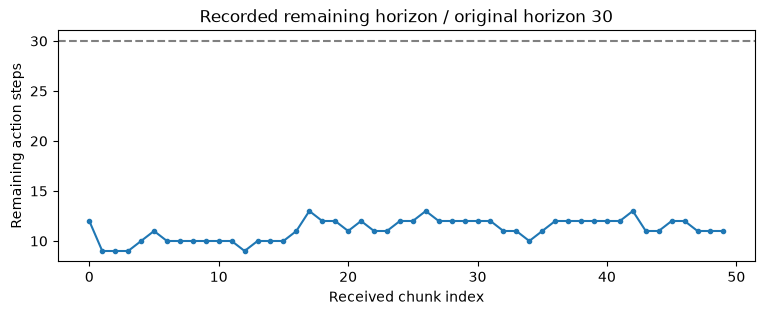

In [6]:
events=[json.loads(line) for line in (DIAG / "strict-events.jsonl").read_text().splitlines()]
chunks=[x for x in events if x["event"]=="received_chunk"]
episodes=[x for x in events if x["event"]=="episode_end"]
summary=json.loads((EVIDENCE / "system/strict_latency_summary.json").read_text())
assert len(chunks)==summary["received_chunks"]==50
assert sum(x["expired"] for x in chunks)==summary["expired_chunks"]==0
assert [x["usable_steps"] for x in chunks]==summary["usable_steps_per_chunk"]
assert episodes==summary["episode"]
assert episodes[0]["applied"]+episodes[0]["held"]==episodes[0]["steps"]==1000
print({"已应用步":episodes[0]["applied"],"保持步":episodes[0]["held"],"最少可用步":min(summary["usable_steps_per_chunk"]),"最多可用步":max(summary["usable_steps_per_chunk"])})
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,3));ax.plot([x["usable_steps"] for x in chunks],marker=".");ax.axhline(30,color="grey",linestyle="--");ax.set(xlabel="Received chunk index",ylabel="Remaining action steps",title="Recorded remaining horizon / original horizon 30");plt.show();plt.close(fig)


## 5. 修复方向与评估条件分开

官方异步路径必须保留原动作合并和时钟。若工程上选择“没有动作时先暂停物理”，下面是实际独立适配器：只改等待分支，添加推理进程存活检查、超时保护和时钟记录。它会改变部署条件，因此保存成新客户端、新目录，成绩单列。不能据此宣称同一官方协议下模型能力提升。

In [7]:
def materialize_client(source, destination):
    source, destination = Path(source), Path(destination)
    original = source.read_text(encoding='utf-8')
    text = original.replace('from .dexjoco_openpi_env import DexJoCoOpenPIEnv',
                            'from dexjoco_openpi_client.dexjoco_openpi_env import DexJoCoOpenPIEnv')
    old = '''                else:
                    pressed_digits = env.stay(continue_stay=in_stay_state)
                    in_stay_state = True
'''
    if text.count(old) != 1:
        raise ValueError('Official client waiting branch changed; review before applying the clock adapter.')
    replacement = '''                else:
                    if not inference_proc.is_alive():
                        raise RuntimeError('Inference process exited while physics was paused.')
                    if time.monotonic() - clock_last_action_wall > 120:
                        raise TimeoutError('Inference did not deliver an action within 120 seconds.')
                    clock_wait_started = time.monotonic()
                    time.sleep(0.001)
                    clock_wait_seconds += time.monotonic() - clock_wait_started
                    continue
'''
    text = text.replace(old, replacement)
    anchor = '            # Episode loop.\n'
    if text.count(anchor) != 1:
        raise ValueError('Official episode loop anchor changed.')
    text = text.replace(anchor, '            clock_wait_seconds = 0.0\n'
        '            clock_started_wall = time.monotonic()\n'
        '            clock_last_action_wall = clock_started_wall\n' + anchor)
    text = text.replace('                    pressed_digits = env.step(action)\n',
        '                    pressed_digits = env.step(action)\n'
        '                    clock_last_action_wall = time.monotonic()\n', 1)
    text = text.replace('                if env.is_done:\n',
        '                if env.is_done:\n'
        '                    import json\n'
        '                    (output_dir / "clock_audit.json").write_text(json.dumps({\n'
        '                        "evaluation_clock": "pause_while_waiting", "physics_steps": timestamp,\n'
        '                        "inference_wait_seconds": clock_wait_seconds,\n'
        '                        "wall_seconds": time.monotonic() - clock_started_wall,\n'
        '                        "success": bool(env.is_success)}))\n', 1)
    text += '\nif __name__ == "__main__":\n    import tyro\n    tyro.cli(main)\n'
    compile(text, str(destination), 'exec')
    destination.write_text(text, encoding='utf-8')
    record = {'source_sha256': hashlib.sha256(original.encode()).hexdigest(),
              'client_sha256': hashlib.sha256(text.encode()).hexdigest(),
              'evaluation_clock': 'pause_while_waiting',
              'contract': 'Official action merging, timestamps, task stepping and termination preserved. '
                          'Physics and its timestamp stop when the action buffer is empty; wall time continues. '
                          'This is a separate deployment condition, not the official asynchronous score.'}
    destination.with_suffix('.source.json').write_text(json.dumps(record, indent=2) + '\n')
    return record


## 6. 在原客户端上生成补丁，逐行检查

只在临时目录生成文件、编译并展示差异，不执行模拟器。下方使用的正是原严格计时客户端，不是为适配器手写的占位文件。

In [8]:
import difflib
original_path=SNAPSHOTS / "eval_dexjoco_openpi.py"
with tempfile.TemporaryDirectory() as temp:
    adapted=Path(temp) / "clock_client.py"
    record=materialize_client(original_path,adapted)
    original=original_path.read_text();changed=adapted.read_text()
    compile(changed,str(adapted),"exec")
    assert "env.stay(continue_stay=in_stay_state)" not in changed
    assert "clock_wait_seconds" in changed and "Inference process exited" in changed
    print("".join(difflib.unified_diff(original.splitlines(True),changed.splitlines(True),fromfile="official",tofile="pause-condition")))
print(record)


--- official
+++ pause-condition
@@ -18,7 +18,7 @@
 from openpi_client import websocket_client_policy
 from scipy.spatial.transform import Rotation as R
 
-from .dexjoco_openpi_env import DexJoCoOpenPIEnv
+from dexjoco_openpi_client.dexjoco_openpi_env import DexJoCoOpenPIEnv
 
 
 @dataclass
@@ -336,6 +336,9 @@
             )
             password = []
 
+            clock_wait_seconds = 0.0
+            clock_started_wall = time.monotonic()
+            clock_last_action_wall = clock_started_wall
             # Episode loop.
             while True:
                 receive_actions(action_queue, actions_buffer, timestamp, dual_arm)
@@ -347,10 +350,17 @@
                     )
                     action = actions_buffer.popleft().action
                     pressed_digits = env.step(action)
+                    clock_last_action_wall = time.monotonic()
                     in_stay_state = False
                 else:
-                    pressed_digits = env.stay(continue_stay=in_stay_

## 7. 复算两种已完成条件，按相同权重和种子配对

官方异步起始／训练后是5/20、3/20；等待暂停物理条件是12/20、14/20。两条件使用相同权重和100–119种子，但评估时钟不同。下面直接从两份记录核对身份，不混成一次模型对照。

In [9]:
conditions={"official_async":json.loads((EVIDENCE / "dexjoco/formal_comparison.json").read_text()),"pause_while_waiting":json.loads((EVIDENCE / "dexjoco_clock/formal_comparison.json").read_text())}
for variant in ("baseline","trained"):
    a,b=(conditions[key][variant] for key in conditions)
    assert a["checkpoint_sha256"]==b["checkpoint_sha256"]
    assert a["seeds"]==b["seeds"]==list(range(100,120))
for name,condition in conditions.items():
    print(name,{key:f'{condition[key]["successes"]}/{condition[key]["episodes"]}' for key in ("baseline","trained")})


official_async {'baseline': '5/20', 'trained': '3/20'}
pause_while_waiting {'baseline': '12/20', 'trained': '14/20'}


## 8. 官方异步条件：起始权重，种子100

此录像来自已有评估回合；模型、条件与种子按下方文件路径标注，不将画面作为单一修复因素的因果证明。

In [10]:
display(Video(str(EVIDENCE / 'dexjoco/videos/base_seed_100.mp4'), embed=True))


## 9. 等待暂停物理条件：相同起始权重，种子100

此录像来自已有评估回合；模型、条件与种子按下方文件路径标注，不将画面作为单一修复因素的因果证明。

In [11]:
display(Video(str(EVIDENCE / 'dexjoco_clock/videos/base_seed_100.mp4'), embed=True))


## 10. 等待暂停物理条件：训练后权重，种子100

此录像来自已有评估回合；模型、条件与种子按下方文件路径标注，不将画面作为单一修复因素的因果证明。

In [12]:
display(Video(str(EVIDENCE / 'dexjoco_clock/videos/trained_seed_100.mp4'), embed=True))


## 最终诊断链

先保证任务适配参数确实加载，再核对统计与动作表示；用真实重置观测预热并恢复随机状态，最后测量官方异步路径的动作等待。若更换时钟条件，保存独立结果与录像。本系列重放已有证据和纯函数测试，未重训或重跑完整评估。